# Phase 4: Ablations of the translation models

We retrained the locked strictly unpaired CycleGAN (M1) and the weakly paired model (M2) of Phase 3 on fresh seeds, changed one component at a time, and scored each run without checkpoint selection, by its mean over the last quarter of training, on 135 validation pairs from 14 donors. On fresh seeds M1 sits on the unpaired accuracy–realism frontier, the best realism that blends of simple unpaired baselines reach at each accuracy (margin beyond it −0.001 in single-cell → bulk and −0.023 in bulk → single-cell). The discriminator is what buys realism: without the adversarial loss, realism stays at the level of the baselines the generators start from (0.128 and 0.092), while the cycle and identity losses alone still move the generators away from them in a direction that costs accuracy (centered R² −0.473 and −1.576). Under the same losses a per-gene affine generator does not become realistic, although per-gene affine baselines can be. M1's move from its start is mostly orthogonal to the correction needed to reach the true partner; its sample-specific component (the cosine with the needed correction above a no-signal null) is 0.072 and 0.152, about half that of paired ridge + spread (0.154 and 0.279). Composition supervision again improves composition under an independent marker probe (at the kept checkpoints, +0.160, 95% CI 0.118–0.260, and +0.196, 95% CI 0.074–0.397). With composition networks retrained on one half of the training donors, whose readings of M2's bulk training profiles are as noisy as on new donors, the last-quarter gain survives in bulk → single-cell (+0.182 against +0.203) but halves in single-cell → bulk (+0.075 against +0.167), where only the weaker readout network changed. These results point Phase 5 toward weight averaging, which improves every seed, and toward losses that change the direction of the generators' moves rather than their length.

## 1. Aim

Phase 3 found that the strictly unpaired CycleGAN (M1) reaches the unpaired accuracy–realism frontier but does not clearly pass it, buying realism at a cost in accuracy and composition, and that composition supervision derived from pairs (M2) repairs composition to about the level of ComBat. Here we change one component of the locked models at a time to find what each does: which loss moves the model, whether the generator uses more than a per-gene affine map, whether the GAN is short of donors or of samples, how much pair information M2's gain needs, and whether "on the frontier" depends on how realism is measured. No new model is selected; the results guide the exploratory Phase 5.

## 2. Data

- **Training: halving 0 of the training split** (582 pairs, 68 donors), as in Phase 3. A halving divides the training donors into two donor-disjoint halves, A and B (Phase 1, §3.5). The models saw the single-cell pseudobulk profiles of half A (33 donors, 288 draws) and the whole-blood bulk profiles of half B (35 donors, 294 draws), and no pair. The data-size ablation (A4) trains on subsets of these halves.
- **Composition networks retrained on half A** (ablation B3): the bulk network $C_B$ on half A's bulk profiles and their paired compositions, and the single-cell network $C_S$ on half A's single-cell profiles. Neither sees any sample of half B.
- **Paired reference:** ridge + spread (§4.5) is fit on all 582 training pairs.
- **Scoring: validation** (135 pairs, 14 donors), with the Phase 1 evaluators, which are fit on training targets only. The test split (119 pairs, 14 donors) is not used.

## 3. Methods

**Notation and metrics** (defined in full in Phase 1, §3, and Phase 3, §3). $x_S$ and $x_B$ are single-cell pseudobulk and whole-blood bulk profiles (log(1 + CP10k) on the 5,000-gene panel), $G_{S\to B}$ and $G_{B\to S}$ the two generators, and $c^*$ the measured composition over six cell-type classes. For a translation $\hat y$ of a validation source whose real partner is $y$:

- **Centered R²** (accuracy): $1 - \lVert \hat y - y\rVert^2 / \lVert y - \mu\rVert^2$, with $\mu$ the per-gene training mean of the target domain, reported as the median over validation pairs; higher is better.
- **Realism**: $1 - 2\,\lvert \text{AUROC} - 0.5 \rvert$, where the AUROC is that of a classifier two-sample test (C2ST; Lopez-Paz and Oquab, 2017): a logistic regression on the top 10 target principal-component (PC) scores and their squares, cross-validated in folds grouped by donor, that separates translations from real validation targets. 1 means indistinguishable, 0 perfectly separable. We call it the **H1 measure**, since it is the realism of Phase 3's hypothesis H1.
- **Unpaired frontier and margin**: the frontier $F(r)$ is the highest realism reached, at centered R² of at least $r$, by any blend of two of mean shift, ComBat (Johnson et al., 2007), CORAL (Sun et al., 2016) and the training-target mean, all fit on the same training halves. A model at accuracy $r$ and realism $s$ has margin $s - F(r)$; a positive margin means that no blend of unpaired baselines is as realistic at that accuracy.
- **Composition R²**: the mean over the six classes of the per-class R² of a composition readout against $c^*$. The **marker probe** is a ridge regression of composition on 28 lineage marker genes (Phase 2), independent of the composition networks that M2 trains against (unlike the ridge probe of Phase 1, which reads all 5,000 genes, as $C_B$ does). The **composition networks** $C_S$ and $C_B$ (Phase 2) read composition from single-cell and bulk profiles; $C_B$ was trained on pairs.
- **Start**: each generator starts exactly at an affine baseline map $s(x)$, mean shift in single-cell → bulk and ComBat in bulk → single-cell (Phase 3, §3.1). The **distance from the start** is the mean over validation sources of the Euclidean distance $\lVert G(x) - s(x)\rVert$.
- **Maximum mean discrepancy (MMD)** (Gretton et al., 2012) between translations and real targets (Phase 1), lower is better.

### 3.1 Protocol

- **References.** The locked M1 is a CycleGAN (Zhu et al., 2017) trained with the least-squares adversarial loss (Mao et al., 2017), the cycle-consistency loss at weight $\lambda_{\text{cyc}} = 20$ and the identity loss (each generator applied to a profile of its own target domain should return it unchanged) at weight 10, with discriminator learning rate $2 \times 10^{-4}$, generators starting at mean shift and ComBat, a learnable per-gene scale and a residual branch. The locked M2 adds to M1 the composition task loss (Hoffman et al., 2018) at weight 10 (Phase 3, §3.1). Each was retrained on **seeds 3–5**. Seeds 0–2 won Phase 3's selection on these validation pairs, so comparing new runs against them would favor the locked models; we used them only to check that the code reproduces Phase 3.
- **One change per ablation.** The data, 20,000 steps, an evaluation every 500 steps and the Phase 3 checkpoint rule are unchanged.
- **Primary readouts (no checkpoint selection).** The **last-quarter readout** of a run is its mean over the last quarter of training (the 11 evaluations at steps 15,000–20,000) of the margin, centered R², realism and marker-probe composition R², per direction. Because the margin is about 0 for anything that stays near a baseline, we also report the move from the start (Δ centered R², Δ realism). Secondary: the selected checkpoint and the last one.
- **Uncertainty.** The SD over the 3 seeds for every readout. For differences in centered R² and marker-probe composition R², also a donor-bootstrap 95% CI (1,000 resamples of the 14 validation donors), computed on the **kept checkpoints**, the generator weights saved at steps 15,000, 17,500 and 20,000, averaged over checkpoints and seeds inside each resample. A C2ST per resample would cost about 5 hours per comparison, so realism and margin get seed SDs only. The CI covers donor sampling, not training noise, and uses the donors that chose the locked models, so it is optimistic.
- **Equivalence check.** With every new option at its default, the code must reproduce the locked M1 on seeds 0–2: the same generators (canonical hashes) and the same margin at every evaluation.

### 3.2 Ablations

| | Change | Question |
|---|---|---|
| A1 | Adversarial loss off (weight 0; discriminators still trained, every random draw unchanged) | Do the cycle and identity losses alone move the generators off their starts? |
| A2 | Affine-only generator ($G(x) = \mathrm{ReLU}(a \odot x + b)$, no residual branch), crossed with the identity loss on or off | Does M1 use cross-gene capacity, or only per-gene scales? |
| A3 | Cycle weight 0 or 40, identity weight held at 10 | What keeps the generators near the data; is weight 20 on a plateau? |
| A4 | Half of each half's donors with all their draws, or all donors with about half of their draws, matched in sample count and age-stratified, a different subset per seed; starts, baselines and frontier refit on each subset | Does the model need more donors or more samples? |
| B0 | M2 retrained on seeds 3–5 | The comparison point for B1–B3 |
| B3 | M2 against composition networks retrained on half A only ($C_B$ on half A's bulk profiles and their compositions, $C_S$ on half A's single-cell profiles) | Does the gain survive labels as noisy as on new donors? |
| B1, B2 | M2 with only the single-cell → bulk task term, or only the bulk → single-cell term | Which term carries the gain? Run only if B3's marker-probe gain over M1 is below half of B0's in a direction where B0 gains (rule fixed before the runs) |

We also report one-at-a-time slices of the Phase 3 selection grid (cycle weight 5, 10 and 20, identity loss, discriminator learning rate, task weight) without new runs; they come from the grid that chose the locked values and are biased toward them.

### 3.3 Analyses without new training

- **Signal or spread.** For each validation source we compared the move from the start, $\delta = G(x) - s(x)$, with the **needed correction** $r = y - s(x)$ to the true partner $y$: the cosine between them, and the length of $\delta$ along $r$ and across it. Two references make these values interpretable: ridge + spread (Phase 1; fit on all 582 training pairs) moving from the same start, an informed correction; and M1's move measured against another donor's profile instead of the true partner, a move with no signal. The **sample-specific component** is the cosine toward the true partner minus the cosine toward the other donor's profile.
- **Realism measure.** We re-measured realism with two alternative C2STs on the top 50 target PCs, a logistic regression on the PCs and their squares and gradient-boosted trees (depth 3, 100 iterations), and with the MMD; each measure gets its own frontier. A measure counts as usable only if it cannot separate real training targets from real validation targets: $|\text{AUROC} - 0.5| < 2\,\text{SD} + 0.05$, with the SD of its paired swap null (rule fixed before any model was scored).
- **Weight averaging.** An exponential moving average (EMA) of the generator weights (decay 0.999) was scored alongside the raw weights at every evaluation of the full-model runs, without affecting training.

## 4. Results

The first code cell records the setup stamp, pins the CPU threads, sets up the caches and loads the validation data, evaluators and frontier of halving 0.

In [1]:
import os, sys, json, warnings
from pathlib import Path
os.environ["PYTHONWARNINGS"] = "ignore:An input array is constant"   # inherited by the worker processes (undefined rank correlations of the constant member)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dgm").is_dir())   # repo root, wherever this runs from
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.linalg import LinAlgWarning

from dgm import paths
from dgm import ablation as ab
from dgm import composition as comp
from dgm import grid, translation as tr
from dgm.frontier import MEAN, envelope, frontier_margin, trace
from dgm.models import canonical_hash, load_frozen, pairs_hash
from dgm.notebook import setup
from dgm.plotting import DOMAIN, INK, INK_2, MUTED, SERIES, THRESHOLD, figure, label, panel_labels, save_show

from scipy.stats import ConstantInputWarning
warnings.filterwarnings("ignore", category=LinAlgWarning)   # ill-conditioned ridge solves inside the evaluators (harmless)
warnings.filterwarnings("ignore", category=ConstantInputWarning)   # rank correlations of the constant training-mean member (undefined, unused)
info = setup(seed=0, notebook="phase4_ablations.ipynb")
comp.deterministic()

RESULTS, FIG = paths.results_dir(4), paths.results_dir(4, "figures")
CACHE = paths.PROCESSED / "phase4"                           # gitignored: one pickle per (configuration, seed, halving) run
CACHE.mkdir(parents=True, exist_ok=True)
MOD4 = paths.REPO / "data" / "models" / "phase4"             # gitignored; hashes in RESULTS/models.json
WORKERS = 6
SEEDS, EQ_SEEDS = (3, 4, 5), (0, 1, 2)                        # fresh seeds; Phase 3's seeds only for the equivalence check
KEEP = (15000, 17500, 20000)                                 # generator weights kept for the no-selection readouts
P3 = json.loads((paths.results_dir(3) / "models.json").read_text())
M1 = tr.config(lambda_cyc=20.0, identity=True)               # the locked settings (Phase 3)
M2 = tr.config(lambda_cyc=20.0, identity=True, lambda_task=10.0)
assert P3["M1_seed0"]["config"] == tr.config_name(M1) and P3["M2_seed0"]["config"] == tr.config_name(M2)

def show_caption(name):
    """Show a saved figure's caption from results/phase4/figures/captions.md (keyed by file name)."""
    f = FIG / "captions.md"
    text = f.read_text() if f.exists() else ""
    if f"\n## {name}\n" in text:
        display(Markdown(text.split(f"\n## {name}\n", 1)[1].split("\n## ", 1)[0].strip()))

ctx0 = tr.SoundLife(0)
P, va = ctx0.pairs, ctx0.va

commit: 4c23c02 | notebook_source: 032f57144246 (= HEAD) | python: 3.10.14 | numpy: 1.26.4 | seed: 0 | torch: 2.8.0+cu129 | cuda: True


### 4.1 Composition networks retrained on half A

**The locked bulk composition network's readings of M2's bulk training profiles were close to the paired truth; retrained on half A, it reads them about as well as new donors.**

**Table 4.1.** Composition R² (mean over the six classes of the per-class R²) of the locked composition networks, trained on all 582 training pairs, and of the same configurations retrained on half A only: $C_B$ on half B's bulk profiles (294 draws, 35 donors; its readings there are M2's bulk-side task targets), $C_B$ on the 135 validation bulk profiles, and $C_S$ on the 135 validation single-cell profiles (14 donors).

In [2]:
# B3's networks: the locked Phase 2 configurations retrained on half A only (before any run, since their registry enters the code key).
REG4 = RESULTS / "models.json"
if not (REG4.exists() and "C_bulk_halfA0" in json.loads(REG4.read_text())):
    ab.half_nets(P, ctx0.half_a, 0, MOD4, REG4)
digest = pairs_hash(P)
half_nets = tuple(load_frozen(f"{n}_halfA0", MOD4, REG4, ctx0.genes, ctx0.classes, digest) for n in ("C_bulk", "C_sc"))
nets = {"locked (all 582 training pairs)": (ctx0.nets["S->B"], ctx0.nets["B->S"]), "retrained on half A": half_nets}
def read(net, x):
    with torch.no_grad():
        return net(torch.as_tensor(x, dtype=torch.float32)).numpy()
net_tab = pd.DataFrame([{"networks": name,
                         "C_B on half B's bulk (M2's pseudo-labels)": comp.comp_r2(read(cb, P.x_bulk[ctx0.half_b]), P.composition[ctx0.half_b]),
                         "C_B on validation bulk": comp.comp_r2(read(cb, P.x_bulk[va]), P.composition[va]),
                         "C_S on validation single-cell": comp.comp_r2(read(cs, P.x_sc[va]), P.composition[va])}
                        for name, (cb, cs) in nets.items()])
net_tab.to_csv(RESULTS / "half_nets_val.csv", index=False)
display(net_tab.rename(columns={"networks": "composition networks"}).style.format("{:.3f}", subset=net_tab.columns[1:]).hide(axis="index")
        .set_caption("Table 4.1. Composition R² of the locked and the half-A composition networks"))

composition networks,C_B on half B's bulk (M2's pseudo-labels),C_B on validation bulk,C_S on validation single-cell
locked (all 582 training pairs),0.978,0.474,0.837
retrained on half A,0.405,0.410,0.760


The locked $C_B$ reads half B's bulk profiles, which were among its training rows, at composition R² 0.978. Retrained on half A, it reads them at 0.405, about its accuracy on new donors (0.410 on validation, against 0.474 for the locked network). $C_S$ retrained on half A reaches 0.760 on validation, against 0.837 for the locked network.

### 4.2 Equivalence with Phase 3

**With every new option at its default, the Phase 4 code reproduces the locked M1 exactly.**

In [3]:
# The Phase 4 code with every option at its default must reproduce the locked M1 (Phase 3, seeds 0-2) exactly:
# the same chosen generators (canonical hashes in results/phase3/models.json) and the same margin at every evaluation.
import hashlib, pickle
KEY = tr.code_key()
print("code key", KEY)
eq = grid.run_grid([M1], EQ_SEEDS, halving=0, workers=WORKERS, cache_dir=CACHE)
P3_KEY = P3["M1_seed0"]["code_key"]
p3_cfg = {k: v for k, v in M1.items() if k not in ("lambda_adv", "affine_only", "ema", "keep_states", "task_terms", "task_nets", "subset", "lambda_id")}
for r in eq:
    assert r["state_hash"] == P3[f"M1_seed{r['seed']}"]["canonical_hash"], f"seed {r['seed']}: generators differ from Phase 3"
    name = hashlib.sha256(json.dumps([P3_KEY, p3_cfg, r["seed"], 0], sort_keys=True, default=str).encode()).hexdigest()[:16]
    old = pickle.loads((paths.PROCESSED / "phase3" / f"run_{name}.pkl").read_bytes())
    assert [e["margin"] for e in old["evals"]] == [e["margin"] for e in r["evals"]], f"seed {r['seed']}: margins differ"
    assert old["best_step"] == r["best_step"]
print(f"equivalence: {len(eq)} runs reproduce Phase 3's chosen generators and every evaluation's margin")

code key 4fb36e8a09c74f62


equivalence: 3 runs reproduce Phase 3's chosen generators and every evaluation's margin


Retrained on Phase 3's seeds 0–2, the three runs reproduce Phase 3's chosen generators and the margin at every evaluation, so every difference below comes from the change being ablated.

### 4.3 Ablations of M1 and M2

**The discriminator buys realism and, with it on, the cycle loss keeps the generators near the data; on fresh seeds, composition supervision again improves composition.**

In [4]:
K = dict(keep_states=KEEP)
GAN = {
    "full model": dict(M1, ema=0.999, **K),
    "A1 adversarial loss off": dict(M1, lambda_adv=0.0, **K),
    "A2 affine-only": dict(M1, affine_only=True, **K),
    "A2 identity loss off": dict(M1, identity=False, **K),
    "A2 affine-only, identity loss off": dict(M1, affine_only=True, identity=False, **K),
    "A3 cycle weight 0": dict(M1, lambda_cyc=0.0, lambda_id=10.0, **K),     # identity weight held at the locked 10
    "A3 cycle weight 40": dict(M1, lambda_cyc=40.0, lambda_id=10.0, **K),
    "A4 half the donors": dict(M1, subset="donors", **K),
    "A4 half the draws": dict(M1, subset="draws", **K),
}
WEAK = {"B0 M2": dict(M2, **K), "B3 M2, half-A networks": dict(M2, task_nets="halfA", **K)}
CONDS = {**GAN, **WEAK}
runs_list = grid.run_grid(list(CONDS.values()), SEEDS, halving=0, workers=WORKERS, cache_dir=CACHE)
RUNS = {name: runs_list[i * len(SEEDS):(i + 1) * len(SEEDS)] for i, name in enumerate(CONDS)}
assert all(r["code_key"] == KEY for rs in RUNS.values() for r in rs)
print(f"{len(runs_list)} runs; failed: {sum(r['failed'] for r in runs_list)}; minutes per run {min(r['minutes'] for r in runs_list):.0f}-{max(r['minutes'] for r in runs_list):.0f}")

33 runs; failed: 0; minutes per run 32-99


In [5]:
# Readouts per run and direction. Primary (no selection): means over the last quarter of training (evaluations at steps
# >= 15,000), and the move from the generator start. Secondary: the selected checkpoint (Phase 3 rule) and the last one.
LQ = ("margin", "r2_centered", "realism", "marker comp_r2", "drift")
def readout(r):
    ev = pd.DataFrame([{k: v for k, v in e.items() if k != "ema"} for e in r["evals"]])
    last_q, start, last = ev[ev.step >= 0.75 * r["cfg"]["steps"]], ev.iloc[0], ev.iloc[-1]
    row = {}
    for d in tr.DIRECTIONS:
        for k in LQ + ((("margin_full",)) if f"{d} margin_full" in ev else ()):
            row[f"{d} {k}"] = last_q[f"{d} {k}"].mean()
        row[f"{d} Δ r2_centered"] = last_q[f"{d} r2_centered"].mean() - start[f"{d} r2_centered"]
        row[f"{d} Δ realism"] = last_q[f"{d} realism"].mean() - start[f"{d} realism"]
        for k in ("margin", "r2_centered", "realism", "marker comp_r2"):
            row[f"{d} {k} (selected)"] = r["best"][f"{d} {k}"]
            row[f"{d} {k} (last)"] = last[f"{d} {k}"]
        for k in ("within_top1", "diversity", "gran_gap"):
            if f"{d} {k}" in r["best"]:
                row[f"{d} {k} (selected)"] = r["best"][f"{d} {k}"]
    row["averaged margin (selected)"], row["chosen step"] = r["best_margin"], r["best_step"]
    return row

read_rows = pd.DataFrame([{"condition": name, "seed": r["seed"], **readout(r)} for name, rs in RUNS.items() for r in rs])
read_rows.to_csv(RESULTS / "ablation_runs_val.csv", index=False)
means = read_rows.groupby("condition", sort=False).mean(numeric_only=True).drop(columns="seed")
sds = read_rows.groupby("condition", sort=False).std(numeric_only=True).drop(columns="seed")
ref_of = lambda name: "B0 M2" if name in WEAK and name != "B0 M2" else "full model"   # M2 itself against M1
diff = pd.DataFrame({name: means.loc[name] - means.loc[ref_of(name)] for name in means.index}).T
means.to_csv(RESULTS / "ablation_means_val.csv"); sds.to_csv(RESULTS / "ablation_sd_val.csv"); diff.to_csv(RESULTS / "ablation_diff_val.csv")

In [6]:
# Donor-bootstrap 95% CIs of the difference from the reference, for centered R² and marker-probe composition R² at the kept
# last-quarter checkpoints (averaged over checkpoints and seeds inside each resample; 1,000 resamples of the 14 donors).
# The CI covers donor sampling only, not training noise (seed SDs are reported next to it).
def kept_outputs(r, d):
    out = []
    for step in KEEP:
        sb, bs = tr.load_generators(r["kept"][step], P.x_sc.shape[1], r["cfg"]["hidden"], r["cfg"]["affine_only"])
        with torch.no_grad():
            out.append((sb if d == "S->B" else bs)(torch.as_tensor(ctx0.src[d])).numpy())
    return out

def per_sample_r2(y, d):
    mu = ctx0.ev[d].mean_
    return 1 - ((y - ctx0.tgt[d]) ** 2).sum(1) / ((ctx0.tgt[d] - mu) ** 2).sum(1)

groups = [np.flatnonzero(P.donor_ids[va] == x) for x in pd.unique(P.donor_ids[va])]
rng_b = np.random.default_rng(0)
BOOT = [np.concatenate([groups[i] for i in rng_b.integers(0, len(groups), len(groups))]) for _ in range(1000)]
cache_out = {}
def stats(name, d):
    if (name, d) not in cache_out:
        ys = [y for r in RUNS[name] for y in kept_outputs(r, d)]
        r2s = np.array([per_sample_r2(y, d) for y in ys])
        mk = [ctx0.marker[d].predict(y) for y in ys]
        cache_out[(name, d)] = (r2s, mk)
    return cache_out[(name, d)]

def boot_diff(name, d):
    (ra, ma), (rb, mb) = stats(name, d), stats(ref_of(name), d)
    C = P.composition[va]
    f = lambda idx: (np.median(ra[:, idx], 1).mean() - np.median(rb[:, idx], 1).mean(),
                     np.mean([comp.comp_r2(m[idx], C[idx]) for m in ma]) - np.mean([comp.comp_r2(m[idx], C[idx]) for m in mb]))
    est, boots = f(np.arange(len(va))), np.array([f(idx) for idx in BOOT])
    lo, hi = np.quantile(boots, [0.025, 0.975], axis=0)
    return {"Δ centered R²": est[0], "Δ centered R² CI": f"{lo[0]:.3f} to {hi[0]:.3f}",
            "Δ marker composition R²": est[1], "Δ marker composition R² CI": f"{lo[1]:.3f} to {hi[1]:.3f}"}

ci_tab = pd.DataFrame([{"condition": name, "direction": label(d), **boot_diff(name, d)}
                       for name in CONDS if name != "full model" for d in tr.DIRECTIONS])
ci_tab.to_csv(RESULTS / "ablation_ci_val.csv", index=False)

**Table 4.2.** Ablations of M1 on the 135 validation pairs (14 donors): last-quarter means ± SD over seeds 3–5, per direction. Columns: margin beyond the unpaired frontier; centered R²; realism; marker-probe composition R²; and the change in centered R² and in realism from the generator's start. For the data-size rows (A4) the margin is against each reduced set's own frontier (§4.4).

**Table 4.3.** The same for M2 (B0) and for M2 trained against the half-A composition networks (B3).

**Table 4.4.** Difference from the reference in centered R² and in marker-probe composition R², per direction: each M1 ablation and M2 (B0) against the full M1 model, and B3 against M2. Mean over the kept checkpoints (steps 15,000, 17,500 and 20,000) and seeds 3–5, with a donor-bootstrap 95% CI (1,000 resamples of the 14 validation donors). Realism and margin have seed SDs only (Tables 4.2–4.3).

In [7]:
SHOW_COLS = {"margin": "margin", "r2_centered": "centered R²", "realism": "realism", "marker comp_r2": "marker composition R²",
             "Δ r2_centered": "Δ centered R² from start", "Δ realism": "Δ realism from start"}
def show_table(rows, title):
    t = pd.concat({label(d): pd.DataFrame({v: [f"{means.loc[n, f'{d} {k}']:.3f} ± {sds.loc[n, f'{d} {k}']:.3f}" for n in rows]
                                           for k, v in SHOW_COLS.items()}, index=rows) for d in tr.DIRECTIONS}, axis=1)
    display(t.style.set_caption(title))
show_table(list(GAN), "Table 4.2. Ablations of M1, validation: last-quarter means ± SD over seeds 3–5")
show_table(list(WEAK), "Table 4.3. Ablations of M2, validation: last-quarter means ± SD over seeds 3–5")
display(ci_tab.style.format("{:.3f}", subset=["Δ centered R²", "Δ marker composition R²"]).hide(axis="index")
        .set_caption("Table 4.4. Difference from the reference (M1; M2 for B3) at the kept checkpoints, validation, with donor-bootstrap 95% CIs"))

condition,direction,Δ centered R²,Δ centered R² CI,Δ marker composition R²,Δ marker composition R² CI
A1 adversarial loss off,single-cell → bulk,-0.191,-0.312 to -0.082,0.019,-0.111 to 0.169
A1 adversarial loss off,bulk → single-cell,-1.383,-1.597 to -0.952,-3.004,-5.048 to -2.374
A2 affine-only,single-cell → bulk,-0.086,-0.231 to 0.016,-0.239,-0.399 to -0.142
A2 affine-only,bulk → single-cell,-0.001,-0.053 to 0.077,0.202,0.094 to 0.457
A2 identity loss off,single-cell → bulk,0.025,-0.019 to 0.077,0.071,0.024 to 0.142
A2 identity loss off,bulk → single-cell,0.018,-0.013 to 0.043,-0.112,-0.283 to 0.002
"A2 affine-only, identity loss off",single-cell → bulk,-0.045,-0.263 to 0.120,-0.154,-0.341 to -0.086
"A2 affine-only, identity loss off",bulk → single-cell,-0.519,-0.608 to -0.432,-0.315,-0.619 to -0.161
A3 cycle weight 0,single-cell → bulk,-1.228,-1.442 to -1.035,-0.245,-0.387 to -0.137
A3 cycle weight 0,bulk → single-cell,-1.505,-1.722 to -1.186,-1.341,-2.239 to -1.047


**Table 4.5.** M2 with only the single-cell → bulk task term (B1) or only the bulk → single-cell term (B2), against M2 with both (B0), on the 135 validation pairs (14 donors): last-quarter means ± SD over seeds 3–5, columns as in Table 4.2. B1 and B2 were run only if the pre-specified rule printed below held (§3.2).

In [8]:
# B1/B2 (one task term at a time) run only if B3 keeps less than half of B0's marker-probe composition gain over M1 in
# either direction (fixed before the run). Gains are last-quarter means over seeds 3-5.
gain = {d: {n: means.loc[n, f"{d} marker comp_r2"] - means.loc["full model", f"{d} marker comp_r2"] for n in WEAK} for d in tr.DIRECTIONS}
trigger = any(gain[d]["B0 M2"] > 0 and gain[d]["B3 M2, half-A networks"] < 0.5 * gain[d]["B0 M2"] for d in tr.DIRECTIONS)   # only where M2 gains at all
for d in tr.DIRECTIONS:
    print(f"{label(d)}: marker composition gain over M1, M2 {gain[d]['B0 M2']:+.3f}, M2 with half-A networks {gain[d]['B3 M2, half-A networks']:+.3f}")
print("B1/B2 triggered:", trigger)
if trigger:
    TERMS = {"B1 M2, single-cell → bulk term only": dict(M2, task_terms="sb", **K), "B2 M2, bulk → single-cell term only": dict(M2, task_terms="bs", **K)}
    t_runs = grid.run_grid(list(TERMS.values()), SEEDS, halving=0, workers=WORKERS, cache_dir=CACHE)
    for i, name in enumerate(TERMS):
        RUNS[name] = t_runs[i * len(SEEDS):(i + 1) * len(SEEDS)]
        WEAK[name] = TERMS[name]
    extra = pd.DataFrame([{"condition": n, "seed": r["seed"], **readout(r)} for n in TERMS for r in RUNS[n]])
    extra.to_csv(RESULTS / "ablation_terms_runs_val.csv", index=False)
    means = pd.concat([means, extra.groupby("condition", sort=False).mean(numeric_only=True).drop(columns="seed")])
    sds = pd.concat([sds, extra.groupby("condition", sort=False).std(numeric_only=True).drop(columns="seed")])
    show_table(list(TERMS) + ["B0 M2"], "Table 4.5. M2 with one task term, validation: last-quarter means ± SD over seeds 3–5")

single-cell → bulk: marker composition gain over M1, M2 +0.167, M2 with half-A networks +0.075
bulk → single-cell: marker composition gain over M1, M2 +0.203, M2 with half-A networks +0.182
B1/B2 triggered: True


**Table 4.6.** One-at-a-time slices of the Phase 3 selection grid, without new runs, on the 135 validation pairs (14 donors): per direction, the margin, centered R² and realism at the chosen checkpoints, and the averaged margin (over both directions and the chosen checkpoint's neighboring evaluations; Phase 3, §3.3), each the mean over seeds 0–2. Each row changes one setting of the locked M1 (cycle weight 20, identity loss on, discriminator learning rate $2 \times 10^{-4}$); in this grid the identity weight is half the cycle weight. The task-weight rows are M2 settings. From the grid that chose the locked values, so biased toward them.

In [9]:
# Phase 3 grid slices (no new runs), from the selection grid and therefore biased toward the locked values.
g1, g2 = pd.read_csv(paths.results_dir(3) / "m1_grid_val.csv", index_col=0), pd.read_csv(paths.results_dir(3) / "m2_grid_val.csv", index_col=0)
SLICE = {"cycle weight 5": "identity=True,lambda_cyc=5.0", "cycle weight 10": "identity=True", "cycle weight 20 (locked)": "identity=True,lambda_cyc=20.0",
         "identity loss off": "lambda_cyc=20.0", "discriminator lr 5e-5": "identity=True,lambda_cyc=20.0,lr_d=5e-05"}
TSLICE = {f"task weight {w}": f"identity=True,lambda_cyc=20.0,lambda_task={w}" for w in (0.1, 1.0, 10.0)}
slices = pd.DataFrame([{"slice": k, **{f"{label(d)} {m}": src.loc[v, f"{d} {m}"] for d in tr.DIRECTIONS for m in ("margin", "r2_centered", "realism")},
                        "averaged margin": src.loc[v, "margin_avg"]} for sl, src in ((SLICE, g1), (TSLICE, g2)) for k, v in sl.items()])
slices.to_csv(RESULTS / "grid_slices_val.csv", index=False)
METRIC = {"margin": "margin", "r2_centered": "centered R²", "realism": "realism"}        # display names
slices_show = slices.set_index("slice").rename(index={"discriminator lr 5e-5": "discriminator learning rate 5 × 10⁻⁵"})
slices_show.index.name = "setting"
slices_show.columns = pd.MultiIndex.from_tuples([("both directions", c) if c == "averaged margin" else
                                                 next((label(d), METRIC[m]) for d in tr.DIRECTIONS for m in METRIC if c == f"{label(d)} {m}")
                                                 for c in slices_show.columns])
display(slices_show.style.format("{:.3f}")
        .set_caption("Table 4.6. One-at-a-time slices of the Phase 3 selection grid, validation, mean over seeds 0–2 (biased toward the locked values)"))

**On fresh seeds the strictly unpaired model sits on the frontier.** Its last-quarter margin is −0.001 ± 0.050 in single-cell → bulk and −0.023 ± 0.039 in bulk → single-cell, at centered R² −0.288 and −0.181 and realism 0.742 and 0.533 (Table 4.2).

**The discriminator buys the realism; without it, the cycle and identity losses still move the generators, in a direction that costs accuracy.** With the adversarial loss off (A1), realism stays at the level of the starts (0.128 and 0.092; change from the start −0.026 and −0.031), yet the generators still move away from them and lose accuracy: centered R² −0.473 and −1.576, a difference from the full model of −0.191 (95% CI −0.312 to −0.082) and −1.383 (95% CI −1.597 to −0.952) (Table 4.4). In bulk → single-cell they also lose composition (marker-probe composition R² −2.995). With the adversarial loss on, the cycle loss is what keeps the generators near the data: without it (A3, weight 0) they leave the data altogether (centered R² −1.416 and −1.940). Distance from the start does not by itself cost accuracy: in single-cell → bulk the full model moves further from its start than A1 (Figure 4.3) but loses less accuracy (change from the start −0.195 against −0.381). At cycle weight 40, accuracy and realism barely change (margin −0.019 and −0.033), but single-cell → bulk composition falls by 0.168 (95% CI 0.103–0.249).

**The identity loss costs single-cell → bulk accuracy and composition.** Without it, single-cell → bulk centered R² is −0.239 against −0.288 and marker-probe composition R² 0.483 against 0.394 (difference +0.071, 95% CI 0.024–0.142), and the margin turns slightly positive (+0.032 ± 0.038). In bulk → single-cell the model is slightly worse without it (margin −0.073; composition difference −0.112, 95% CI −0.283 to 0.002). One possible reason is that the identity loss asks the single-cell → bulk generator to leave bulk profiles unchanged, which pulls against its start at the mean shift. The same argument would predict a cost in bulk → single-cell, whose ComBat start also changes profiles, yet there the identity loss helps composition, so the mechanism is untested.

**Under these losses, an affine-only generator does not become realistic.** It stays near the realism of its start (0.064 and 0.115, at or below the start; 0.192 and 0.129 without the identity loss, slightly above the start in single-cell → bulk), although per-gene affine maps can be realistic: ComBat reaches 0.417 in single-cell → bulk and mean shift 0.575 in bulk → single-cell (Phase 3, Table 3.6). The training, not the form of the map, keeps it away from a realistic affine map; with the residual branch, M1 gets there. The affine-only model keeps more bulk → single-cell composition than M1 (+0.202, 95% CI 0.094–0.457) and less single-cell → bulk composition (−0.239, 95% CI −0.399 to −0.142).

**On fresh seeds, composition supervision again improves composition.** M2 exceeds M1 under the marker probe by 0.160 (95% CI 0.118–0.260) in single-cell → bulk and 0.196 (95% CI 0.074–0.397) in bulk → single-cell (Table 4.4), with last-quarter means of 0.561 against 0.394 and 0.216 against 0.013.

**With composition networks retrained on half A, the gain survives in bulk → single-cell but halves in single-cell → bulk.** Against the half-A networks (B3), M2's last-quarter gain over M1 is +0.182 against +0.203 in bulk → single-cell, and +0.075 against +0.167 in single-cell → bulk (difference from M2 at the kept checkpoints −0.024, 95% CI −0.092 to 0.054, and −0.088, 95% CI −0.202 to −0.024). B3's margin is +0.088 ± 0.026 and +0.008 ± 0.043, against +0.002 ± 0.087 and −0.031 ± 0.035 for M2, within M2's seed spread. B3 changes two things at once: the networks' readings of half B become out-of-sample, and the networks are trained on 288 rather than 582 pairs. The two task terms see this differently. The bulk → single-cell term compares $C_S$'s reading of the translated profile with $C_B$'s reading of the bulk input, so its targets become out-of-sample labels. The single-cell → bulk term compares $C_B$'s reading of the translated profile with the measured composition, so its targets are unchanged and only its readout network is weaker; and since that network was trained on half A's own bulk pairs, the term can still pull each translation toward its sample's true bulk profile. Since either term alone raises single-cell → bulk composition (below), the halving there cannot be attributed to label quality.

**Each task term alone gives most of the gain, in both directions** (seed SDs only). B3 kept less than half of M2's single-cell → bulk gain, so by the pre-specified rule we ran the single-term models. With only the single-cell → bulk term, marker-probe composition R² is 0.531 and 0.173; with only the bulk → single-cell term, 0.509 and 0.129; with both, 0.561 and 0.216 (Table 4.5), so a single term gives 57–82% of M2's gain over M1. The bulk → single-cell term alone helps its own direction least (0.129 against 0.173). The two terms overlap, and each reaches the other direction, plausibly through the cycle loss.

### 4.4 Data size: donors or draws

**Halving the data costs realism whether donors or draws are removed; the evidence that donors matter more is weak.**

**Table 4.7.** Training-set sizes of the data-size ablation (A4) and of the full halves: single-cell and bulk profiles and donors, mean over the three subset draws (one per seed, 3–5).

**Table 4.8.** Data size on the 135 validation pairs (14 donors), last-quarter means over seeds 3–5, per direction: the margin against each reduced set's own frontier, the margin against the full halves' frontier (the full model's own frontier, so blank for it), centered R² and realism.

In [10]:
A4 = ["full model", "A4 half the donors", "A4 half the draws"]
rows = []
for name in A4:
    for r in RUNS[name]:
        rows.append({"condition": name, "seed": r["seed"], "single-cell rows": len(r["rows_s"]), "bulk rows": len(r["rows_b"]),
                     "single-cell donors": len(np.unique(P.donor_ids[r["rows_s"]])), "bulk donors": len(np.unique(P.donor_ids[r["rows_b"]]))})
sizes = pd.DataFrame(rows)
sizes.to_csv(RESULTS / "a4_subsets.csv", index=False)
json.dump({f"{n} seed {r['seed']}": {"single-cell rows": P.sample_ids[r["rows_s"]].tolist(), "bulk rows": P.sample_ids[r["rows_b"]].tolist()}
           for n in A4[1:] for r in RUNS[n]}, open(RESULTS / "a4_subset_rows.json", "w"), indent=1)
cols = [f"{d} {k}" for d in tr.DIRECTIONS for k in ("margin", "margin_full", "r2_centered", "realism")]
a4 = means.loc[A4, [c for c in cols if c in means.columns]]
display(sizes.groupby("condition", sort=False).mean(numeric_only=True).drop(columns="seed")
        .rename(columns={"single-cell rows": "single-cell profiles", "bulk rows": "bulk profiles"}).style.format("{:.0f}")
        .set_caption("Table 4.7. Training-set sizes, mean over the 3 subset draws"))
A4_SHOW = {"margin": "margin (own frontier)", "margin_full": "margin (full halves' frontier)", "r2_centered": "centered R²", "realism": "realism"}
a4_show = a4.copy()
a4_show.columns = pd.MultiIndex.from_tuples([(label(c.split(" ", 1)[0]), A4_SHOW[c.split(" ", 1)[1]]) for c in a4.columns])
display(a4_show.style.format("{:.3f}", na_rep="").set_caption("Table 4.8. Data size, validation: last-quarter means over seeds 3–5"))

,single-cell profiles,bulk profiles,single-cell donors,bulk donors
condition,,,,
full model,288,294,33,35
A4 half the donors,141,142,16,17
A4 half the draws,141,142,33,35


Each reduced set has about 141 single-cell and 142 bulk profiles: 16 and 17 donors with all their draws, or all 33 and 35 donors with about half of their draws (Table 4.7). Realism falls from 0.742 to 0.577 with fewer donors and 0.594 with fewer draws in single-cell → bulk, and from 0.533 to 0.312 and 0.376 in bulk → single-cell. Centered R² changes little in single-cell → bulk and rises in bulk → single-cell (by 0.057, 95% CI 0.032–0.121, with fewer donors and 0.122, 95% CI 0.077–0.173, with fewer draws; Table 4.4): with less data the model moves along the trade-off, toward accuracy. Against each reduced set's own frontier, the margin is −0.058 and −0.070 in single-cell → bulk and −0.166 and −0.078 in bulk → single-cell, with seed SDs up to 0.186 (Table 4.2). With the same 20,000 steps, each profile of a reduced set is seen about twice as often.

### 4.5 Signal or spread

**M1's move away from its start is mostly orthogonal to the needed correction; its sample-specific component is about half that of paired regression.**

**Table 4.9.** The move from the generator's start, $\delta = G(x) - s(x)$, against the needed correction to the true partner, $r = y - s(x)$, per direction, medians over the 135 validation samples (14 donors) pooled over seeds and checkpoints: the length of the move $\lVert\delta\rVert$, the length of the needed correction $\lVert r\rVert$, their cosine, and the length of $\delta$ along $r$ and across it (Euclidean, in log(1 + CP10k) units). M1 at Phase 3's chosen checkpoints (seeds 0–2, selection-biased), M1 and M2 at the kept last-quarter checkpoints (seeds 3–5), and the paired reference ridge + spread (fit on all 582 training pairs). In the null rows the true partner is replaced by a real profile of another donor.

In [11]:
# P0: the move from the start, delta = G(x) - start(x), against the needed correction r = y - start(x), per validation
# sample. References: ridge + spread (paired, all training pairs) moving from the same start (an informed correction), and
# M1 against a null target: another donor's real profile (a move with no signal).
from dgm.baselines import RidgeSpread
tr_idx = P.idx("train")
def start_of(d):
    a0, b0 = ctx0.init[d]
    return np.maximum(ctx0.src[d] * a0 + b0, 0)

rs_out = {}
for d in tr.DIRECTIONS:
    src, tgt = (P.x_sc, P.x_bulk) if d == "S->B" else (P.x_bulk, P.x_sc)
    rs_out[d] = RidgeSpread().fit(src[tr_idx], tgt[tr_idx], P.donor_ids[tr_idx], comp=P.composition[tr_idx], age=P.age_group[tr_idx],
                                  genes=ctx0.genes, direction=d).translate(src[va])
rng_p0 = np.random.default_rng(0)
donors_va = P.donor_ids[va]
other = np.array([rng_p0.choice(np.flatnonzero(donors_va != donors_va[i])) for i in range(len(va))])   # another donor's draw

def p3_states(model):
    out = []
    for s in EQ_SEEDS:
        blob = torch.load(paths.REPO / "data" / "models" / "phase3" / f"{model}_seed{s}.pt", weights_only=False)
        out.append(blob["state"])
    return out

def outputs_of(state, d, affine=False):
    sb, bs = tr.load_generators(state, P.x_sc.shape[1], 512, affine)
    with torch.no_grad():
        return (sb if d == "S->B" else bs)(torch.as_tensor(ctx0.src[d])).numpy()

p0_rows = []
for d in tr.DIRECTIONS:
    st, y = start_of(d), ctx0.tgt[d]
    sets = {"M1, chosen checkpoints (seeds 0-2, selection-biased)": [outputs_of(s, d) for s in p3_states("M1")],
            "M1, last-quarter checkpoints (seeds 3-5)": [y_ for r in RUNS["full model"] for y_ in kept_outputs(r, d)],
            "M2, last-quarter checkpoints (seeds 3-5)": [y_ for r in RUNS["B0 M2"] for y_ in kept_outputs(r, d)],
            "ridge + spread (paired reference)": [rs_out[d]]}
    for name, outs in sets.items():
        dec = pd.concat([ab.move_decomposition(st, o, y) for o in outs])
        p0_rows.append({"direction": label(d), "translations": name, "target": "true partner", **dec.median().to_dict()})
    dec = pd.concat([ab.move_decomposition(st, o, y[other]) for o in sets["M1, last-quarter checkpoints (seeds 3-5)"]])
    p0_rows.append({"direction": label(d), "translations": "M1, last-quarter checkpoints (seeds 3-5)", "target": "another donor (null)", **dec.median().to_dict()})
    dec = ab.move_decomposition(st, rs_out[d], y[other])
    p0_rows.append({"direction": label(d), "translations": "ridge + spread (paired reference)", "target": "another donor (null)", **dec.median().to_dict()})
p0 = pd.DataFrame(p0_rows)
p0.to_csv(RESULTS / "p0_move_decomposition_val.csv", index=False)
P0_SHOW = {"move": "move ‖δ‖", "needed": "needed correction ‖r‖", "cos": "cosine", "along": "along r", "across": "across r"}
p0_show = p0.rename(columns=P0_SHOW).assign(translations=p0.translations.str.replace("0-2", "0–2").str.replace("3-5", "3–5"))
display(p0_show.style.format("{:.3f}", subset=list(P0_SHOW.values())).hide(axis="index")
        .set_caption("Table 4.9. The move from the generator start against the needed correction, medians over validation samples"))
# The sample-specific part: the cosine toward the true partner minus the cosine toward another donor's profile.
for d in tr.DIRECTIONS:
    q = p0[p0.direction == label(d)].set_index(["translations", "target"])["cos"]
    print(f"{label(d)}: cosine excess over the null, M1 (seeds 3-5) "
          f"{q[('M1, last-quarter checkpoints (seeds 3-5)', 'true partner')] - q[('M1, last-quarter checkpoints (seeds 3-5)', 'another donor (null)')]:.3f}, "
          f"ridge + spread {q[('ridge + spread (paired reference)', 'true partner')] - q[('ridge + spread (paired reference)', 'another donor (null)')]:.3f}")

direction,translations,target,move ‖δ‖,needed correction ‖r‖,cosine,along r,across r
single-cell → bulk,"M1, chosen checkpoints (seeds 0–2, selection-biased)",true partner,6.035,8.744,0.217,1.222,5.610
single-cell → bulk,"M1, last-quarter checkpoints (seeds 3–5)",true partner,6.080,8.744,0.225,1.204,5.649
single-cell → bulk,"M2, last-quarter checkpoints (seeds 3–5)",true partner,5.258,8.744,0.211,0.996,4.988
single-cell → bulk,ridge + spread (paired reference),true partner,5.882,8.744,0.516,3.007,5.045
single-cell → bulk,"M1, last-quarter checkpoints (seeds 3–5)",another donor (null),6.080,10.234,0.153,0.820,5.787
single-cell → bulk,ridge + spread (paired reference),another donor (null),5.882,10.234,0.361,2.110,5.426
bulk → single-cell,"M1, chosen checkpoints (seeds 0–2, selection-biased)",true partner,2.820,4.991,0.141,0.394,2.753
bulk → single-cell,"M1, last-quarter checkpoints (seeds 3–5)",true partner,2.752,4.991,0.128,0.352,2.698
bulk → single-cell,"M2, last-quarter checkpoints (seeds 3–5)",true partner,2.683,4.991,0.160,0.444,2.600
bulk → single-cell,ridge + spread (paired reference),true partner,4.015,4.991,0.572,2.182,3.286


single-cell → bulk: cosine excess over the null, M1 (seeds 3-5) 0.072, ridge + spread 0.154
bulk → single-cell: cosine excess over the null, M1 (seeds 3-5) 0.152, ridge + spread 0.279


The median cosine between the move and the needed correction is 0.225 in single-cell → bulk and 0.128 in bulk → single-cell (seeds 3–5; 0.217 and 0.141 for the chosen checkpoints of seeds 0–2), against 0.516 and 0.572 for ridge + spread, a paired regression (Table 4.9). Part of any move toward real profiles points along the needed correction whatever the partner: against another donor's profile the cosine is 0.153 and −0.024 for M1 and 0.361 and 0.293 for ridge + spread. The excess for the true partner, the sample-specific component, is 0.072 and 0.152 for M1 against 0.154 and 0.279 for ridge + spread (printed below Table 4.9). In single-cell → bulk, ridge + spread moves about as far as M1 (5.882 against 6.080) but 2.5 times as far along the needed correction (3.007 against 1.204), much of it toward the real population rather than the partner.

**M2's composition gain does not come from moving less.** At the same distance from the start, M2's translations carry more composition than M1's (Figure 4.2); in single-cell → bulk M2 also moves slightly less (5.258 against 6.080).

### 4.6 Is "on the frontier" specific to the realism measure?

**Only the H1 realism measure passes calibration in both directions.**

**Table 4.10.** Calibration of the realism measures, per direction: the AUROC of each measure's classifier separating real training targets from real validation targets (disjoint donors; donor-grouped 5-fold cross-validation), and the mean and SD of its paired swap null around M1 on the 135 validation pairs (14 donors). A measure is usable if $|\text{AUROC} - 0.5| < 2\,\text{SD} + 0.05$. Measures: the H1 measure (logistic regression on the top 10 target PCs and their squares), the same classifier on the top 50 PCs, and gradient-boosted trees on the top 50 PCs.

**Table 4.11.** Margin beyond each measure's own frontier, per direction, for M1 and M2 at Phase 3's chosen checkpoints (mean over seeds 0–2) and for M1 at the kept last-quarter checkpoints of seeds 3–5 (mean over seeds and checkpoints). Under MMD the margin is a difference in −MMD, not comparable with the realism margins.

In [12]:
# P1: realism under two alternative classifier two-sample tests on the top 50 target PCs, each with its own frontier, and
# MMD (lower is better; its frontier is built on -MMD; not calibrated). Each classifier measure is calibrated first: real
# training against real validation targets (unpaired, donor-grouped folds) and the paired swap null around M1; a measure
# fails if |AUROC - 0.5| >= 2 x null SD + 0.05. Settings are fixed in dgm.ablation.c2st_alt before any model is scored.
from dgm.baselines import CORAL, ComBat, MeanShift
ALT = ("logistic50", "boosted50")
donors_va = P.donor_ids[va]
def unpaired_c2st(kind, d):
    """Real training targets against real validation targets (disjoint donors), donor-grouped 5-fold CV: a measure that
    separates two sets of real profiles flags PCA inflation on training samples or donor-set differences, not translation."""
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import GroupKFold
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    ev = ctx0.ev[d]
    real_tr = (P.x_bulk if d == "S->B" else P.x_sc)[tr_idx]
    k = 10 if kind == "H1 (logistic, 10 PCs)" else 50
    z = ev.pca_.transform(np.vstack([real_tr, ctx0.tgt[d]]))[:, :k]
    if kind != "boosted50":
        z = np.hstack([z, z ** 2])
    lab = np.r_[np.ones(len(real_tr)), np.zeros(len(va))]
    grp = np.r_[P.donor_ids[tr_idx], donors_va]
    proba = np.zeros(len(z))
    for trn, te in GroupKFold(n_splits=5).split(z, lab, grp):
        clf = (HistGradientBoostingClassifier(max_depth=3, max_iter=100, learning_rate=0.1, random_state=0) if kind == "boosted50"
               else make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000)))
        proba[te] = clf.fit(z[trn], lab[trn]).predict_proba(z[te])[:, 1]
    return float(roc_auc_score(lab, proba))

def realisms(y, d):
    ev, t = ctx0.ev[d], ctx0.tgt[d]
    out = {k: 1 - 2 * abs(ab.c2st_alt(k, ev, y, t, donors_va) - 0.5) for k in ALT}
    m, _ = ev.score(y, t, P.composition[va], P.age_group[va], donors_va, ctx0.classes)
    out["H1 (logistic, 10 PCs)"], out["-MMD"], out["r2"] = 1 - 2 * abs(m["c2st_auroc"] - 0.5), -m["mmd"], m["r2_centered"]
    return out

tr_idx = P.idx("train")
m1_ref = [outputs_of(s, d) for d in tr.DIRECTIONS for s in p3_states("M1")[:1]]   # swap null around M1 (seed 0) vs real
cal = []
for i, d in enumerate(tr.DIRECTIONS):
    for k in ("H1 (logistic, 10 PCs)",) + ALT:
        if k == "H1 (logistic, 10 PCs)":
            from dgm.metrics import c2st_null, DIST_PCS
            ev = ctx0.ev[d]
            mu, sd = c2st_null(ev.pca_.transform(m1_ref[i])[:, :DIST_PCS], ev.pca_.transform(ctx0.tgt[d])[:, :DIST_PCS], donors_va, n_perm=50)
        else:
            mu, sd = ab.c2st_alt_null(k, ctx0.ev[d], m1_ref[i], ctx0.tgt[d], donors_va)
        cal.append({"direction": label(d), "measure": k, "real training vs real validation targets, AUROC": unpaired_c2st(k, d),
                    "swap null mean": mu, "swap null SD": sd})
cal = pd.DataFrame(cal)
# Usability rule (fixed before any model's P1 value was read): |AUROC - 0.5| < 2 x swap-null SD + 0.05 on real vs real.
cal["usable"] = (cal["real training vs real validation targets, AUROC"] - 0.5).abs() < 2 * cal["swap null SD"] + 0.05
cal.to_csv(RESULTS / "p1_calibration_val.csv", index=False)
MEAS = {"H1 (logistic, 10 PCs)": "H1 measure (logistic, 10 PCs)", "logistic50": "logistic, 50 PCs",
        "boosted50": "gradient-boosted trees, 50 PCs", "-MMD": "MMD (margin in −MMD)"}      # display names
cal_show = cal.assign(measure=cal.measure.map(MEAS), usable=cal.usable.map({True: "yes", False: "no"}))
display(cal_show.style.format("{:.3f}", subset=cal_show.columns[2:5]).hide(axis="index").set_caption("Table 4.10. Calibration of the realism measures"))

# Frontier members and blends under every measure, and the models' positions.
p1_rows, fronts = [], {}
for d in tr.DIRECTIONS:
    src, tgt = (P.x_sc, P.x_bulk) if d == "S->B" else (P.x_bulk, P.x_sc)
    s_idx, t_idx = (ctx0.half_a, ctx0.half_b) if d == "S->B" else (ctx0.half_b, ctx0.half_a)
    members = {m.name: m.fit(src[s_idx], tgt[t_idx]).translate(src[va]) for m in (MeanShift(), ComBat(), CORAL())}
    members[MEAN] = np.tile(tgt[t_idx].mean(0), (len(va), 1))
    scored = {}                                                          # each blend scored once under all measures
    def score_all(y, d=d):
        key = hash(y.tobytes())
        if key not in scored:
            scored[key] = realisms(y, d)
        return scored[key]
    for meas in ("H1 (logistic, 10 PCs)",) + ALT + ("-MMD",):
        fronts[(d, meas)] = trace(members, lambda y, meas=meas: (score_all(y)["r2"], score_all(y)[meas]))
    ref_f = ctx0.frontier[d][["a", "b", "w", "realism"]].reset_index(drop=True)
    new_f = fronts[(d, "H1 (logistic, 10 PCs)")][["a", "b", "w", "realism"]].reset_index(drop=True)
    assert (ref_f[["a", "b", "w"]] == new_f[["a", "b", "w"]]).all().all() and (ref_f["realism"] - new_f["realism"]).abs().max() < 1e-3
    models = {"M1, chosen (seeds 0-2)": [outputs_of(s, d) for s in p3_states("M1")],
              "M2, chosen (seeds 0-2)": [outputs_of(s, d) for s in p3_states("M2")],
              "M1, kept last-quarter checkpoints (seeds 3-5)": [y_ for r in RUNS["full model"] for y_ in kept_outputs(r, d)]}
    for name, ys in models.items():
        vals = [realisms(y, d) for y in ys]
        for meas in ("H1 (logistic, 10 PCs)",) + ALT + ("-MMD",):
            margins = [frontier_margin(fronts[(d, meas)], v["r2"], v[meas])[0] for v in vals]
            p1_rows.append({"direction": label(d), "model": name, "measure": meas, "margin": np.mean(margins), "margin SD": np.std(margins, ddof=1)})
p1 = pd.DataFrame(p1_rows)
p1.to_csv(RESULTS / "p1_margins_val.csv", index=False)
pd.concat([f.assign(direction=d, measure=m) for (d, m), f in fronts.items()]).to_csv(RESULTS / "p1_frontiers_val.csv", index=False)
p1_show = p1.assign(measure=p1.measure.map(MEAS), model=p1.model.str.replace("0-2", "0–2").str.replace("3-5", "3–5"))
p1_show = p1_show.pivot_table(index=["direction", "model"], columns="measure", values="margin", sort=False)[list(MEAS.values())]
display(p1_show.style.format("{:.3f}").set_caption("Table 4.11. Margin beyond each measure's own frontier, validation"))

direction,measure,"real training vs real validation targets, AUROC",swap null mean,swap null SD,usable
single-cell → bulk,"H1 measure (logistic, 10 PCs)",0.526,0.504,0.039,yes
single-cell → bulk,"logistic, 50 PCs",0.915,0.509,0.045,no
single-cell → bulk,"gradient-boosted trees, 50 PCs",0.852,0.512,0.040,no
bulk → single-cell,"H1 measure (logistic, 10 PCs)",0.611,0.505,0.041,yes
bulk → single-cell,"logistic, 50 PCs",0.668,0.509,0.033,no
bulk → single-cell,"gradient-boosted trees, 50 PCs",0.566,0.514,0.046,yes


The classifiers on the top 50 PCs separate real training from real validation targets (AUROC 0.915 and 0.852 in single-cell → bulk; 0.668 for the logistic one in bulk → single-cell), so they pick up the inflated spread of training samples along PCs fit on them, and differences between donor sets, rather than realism. Only the gradient-boosted classifier in bulk → single-cell passes (0.566), as does the H1 measure in both directions (0.526 and 0.611) (Table 4.10). Under that one usable alternative, M1 lies well inside the frontier in bulk → single-cell (margin −0.155 for the chosen seeds 0–2 and −0.167 for seeds 3–5, against −0.026 and −0.015 under the H1 measure; Table 4.11). The seed SD of the boosted-classifier margin for seeds 3–5 is 0.040. The H1 measure's own bulk → single-cell calibration (0.611) is close to its limit (0.633). Under MMD, which has no calibration or null here and whose margins are differences in −MMD, not comparable with realism margins, M1 is slightly beyond its frontier (0.040 to 0.046 and 0.004 to 0.005).

### 4.7 Weight averaging

**Averaging the generator weights helps slightly, in every seed.**

**Table 4.12.** Raw and averaged (EMA, decay 0.999) generator weights of the full-model runs on the 135 validation pairs (14 donors): margin, centered R² and realism per direction, last-quarter means over seeds 3–5 and their SD over seeds.

In [13]:
# EMA of the generator weights (decay 0.999), scored alongside the raw weights in the full-model runs (seeds 3-5).
rows = []
for r in RUNS["full model"]:
    for e in r["evals"]:
        if e["step"] >= 0.75 * r["cfg"]["steps"]:
            rows.append({"seed": r["seed"], "step": e["step"], **{f"{w} {d} {k}": src[f"{d} {k}"] for w, src in (("raw", e), ("EMA", e["ema"]))
                                                                for d in tr.DIRECTIONS for k in ("margin", "r2_centered", "realism")}})
ema_tab = pd.DataFrame(rows)
ema_tab.to_csv(RESULTS / "ema_last_quarter_val.csv", index=False)
ema_sum = ema_tab.drop(columns="step").groupby("seed").mean()
EMA_METRIC = {"margin": "margin", "r2_centered": "centered R²", "realism": "realism"}      # display names
order = [(w, d, k) for d in tr.DIRECTIONS for k in EMA_METRIC for w in ("raw", "EMA")]
ema_show = pd.DataFrame({"mean": ema_sum.mean(), "SD over seeds": ema_sum.std()}).T[[f"{w} {d} {k}" for w, d, k in order]]
ema_show.columns = pd.MultiIndex.from_tuples([(label(d), EMA_METRIC[k], w) for w, d, k in order])
display(ema_show.style.format("{:.3f}").set_caption("Table 4.12. Raw and averaged (EMA) generator weights, validation: last-quarter means over seeds 3–5"))
for d in tr.DIRECTIONS:
    for k in ("margin", "r2_centered"):
        print(f"{label(d)} {EMA_METRIC[k]}: EMA minus raw per seed", (ema_sum[f"EMA {d} {k}"] - ema_sum[f"raw {d} {k}"]).round(3).tolist())

single-cell → bulk margin: EMA minus raw per seed [0.054, 0.015, 0.024]
single-cell → bulk centered R²: EMA minus raw per seed [0.036, 0.015, 0.026]
bulk → single-cell margin: EMA minus raw per seed [0.006, 0.02, 0.028]
bulk → single-cell centered R²: EMA minus raw per seed [0.016, 0.025, 0.024]


Over the last quarter of training the averaged weights reach margins of +0.030 and −0.006, against −0.001 and −0.023 for the raw weights, and centered R² of −0.262 and −0.159 against −0.288 and −0.181, at no extra training. The means overlap within seed SDs, but the margin and centered R² improve in all three seeds and both directions (margin +0.054, +0.015 and +0.024 in single-cell → bulk, +0.006, +0.020 and +0.028 in bulk → single-cell).

### 4.8 Figures

Figure 4.1 places the ablations of M1 and M2 on the accuracy–realism plane with the unpaired frontier (§4.3). Figure 4.2 shows composition against the distance from the start for M1 and M2 (§4.5), and Figure 4.3 the distance from the start over training (§4.3).

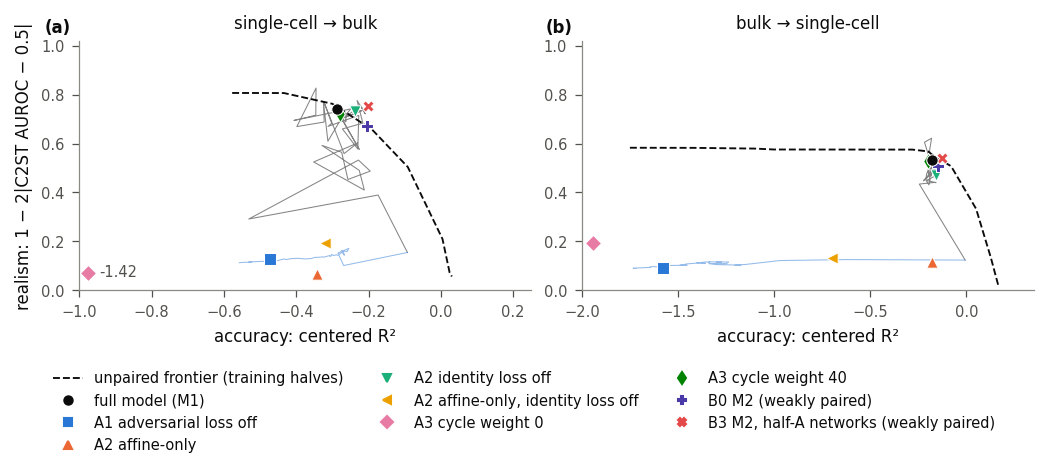

**The discriminator moves the model up to the unpaired frontier; without it, or with an affine-only generator under the same losses, the model stays unrealistic.** Each panel places translations of the 135 validation sources (14 donors) by accuracy and realism: (a) single-cell → bulk, (b) bulk → single-cell. Accuracy (x-axis) is the centered R², the R² of translated against real target profiles after removing each gene's training mean; realism (y-axis) is 1 − 2|AUROC − 0.5|, where AUROC is that of a classifier two-sample test (C2ST) separating translated from real targets. Higher is better on both axes. Markers are last-quarter means over seeds 3–5 (the 11 evaluations at steps 15,000–20,000) of the locked strictly unpaired model (full model, M1), its ablations A1–A3, and the weakly paired model M2 with the locked (B0) and the half-A (B3) composition networks; M2's composition loss uses networks trained on pairs, so B0 and B3 are marked as weakly paired. The dashed curve is the unpaired frontier: the best realism reached at each accuracy by blending mean shift, ComBat, CORAL and the training-target mean, all fit on the same training halves as the models. Thin lines trace the full model (gray) and the model without the adversarial loss (blue) over training for seed 3. The x-axes are cut at −1.0 in (a) and −2.0 in (b); the cycle-weight-0 model in (a), at centered R² −1.42, is drawn at the left edge and labeled with its value. The data-size ablations have frontiers of their own and are reported in Table 4.8.

In [14]:
# Figure 4.1: every condition on the accuracy-realism plane (last-quarter means) with the unpaired frontier, and the
# trajectories of the full model, adversarial loss off and cycle weight 0 over training (seed 3).
frontier = pd.read_csv(paths.results_dir(1) / "frontier_val_halves.csv")
fig, ax = figure("double", 3.0, 1, 2)
MARK = {"full model": (INK, "o"), "A1 adversarial loss off": (SERIES[0], "s"), "A2 affine-only": (SERIES[1], "^"),
        "A2 identity loss off": (SERIES[2], "v"), "A2 affine-only, identity loss off": (SERIES[3], "<"),
        "A3 cycle weight 0": (SERIES[4], "D"), "A3 cycle weight 40": (SERIES[5], "d"), "B0 M2": (SERIES[6], "P"), "B3 M2, half-A networks": (SERIES[7], "X")}
LEG = {"full model": "full model (M1)", "B0 M2": "B0 M2 (weakly paired)", "B3 M2, half-A networks": "B3 M2, half-A networks (weakly paired)"}   # legend text
XL = {"S->B": (-1.0, 0.25), "B->S": (-2.0, 0.35)}                  # conditions beyond the left edge are drawn at it, with their value
for a, d in zip(ax, tr.DIRECTIONS):
    lo, hi = XL[d]
    env = envelope(frontier[(frontier.halving == 0) & (frontier.direction == d)])
    a.plot(env["r2_centered"], env["realism"], color=INK, lw=0.9, ls="--", zorder=1)
    for name in ("full model", "A1 adversarial loss off"):
        ev = pd.DataFrame([{k: v for k, v in e.items() if k != "ema"} for e in RUNS[name][0]["evals"]])
        a.plot(ev[f"{d} r2_centered"].clip(lower=lo), ev[f"{d} realism"], color=MARK[name][0], lw=0.5, alpha=0.5, zorder=2)
    for name, (col, mk) in MARK.items():
        x, y = means.loc[name, f"{d} r2_centered"], means.loc[name, f"{d} realism"]
        a.scatter(max(x, lo + 0.02 * (hi - lo)), y, s=30, color=col, marker=mk, edgecolor="white", lw=0.5, zorder=4 if name == "full model" else 3)   # reference on top
        if x < lo:
            a.annotate(f"{x:.2f}", (lo + 0.02 * (hi - lo), y), xytext=(5, -2), textcoords="offset points", fontsize=7, color=INK_2)
    a.set(xlabel="accuracy: centered R²", ylabel="realism: 1 − 2|C2ST AUROC − 0.5|" if d == "S->B" else "", title=label(d), ylim=(0, 1.02), xlim=(lo, hi))
from matplotlib.lines import Line2D
handles = [Line2D([], [], color=INK, lw=0.9, ls="--", label="unpaired frontier (training halves)")] + \
          [Line2D([], [], ls="", marker=mk, color=col, label=LEG.get(n, n)) for n, (col, mk) in MARK.items()]
fig.legend(handles=handles, loc="outside lower center", ncol=3)
panel_labels(ax)
save_show(fig, FIG, "4.1_ablations_plane")
show_caption("4.1_ablations_plane")

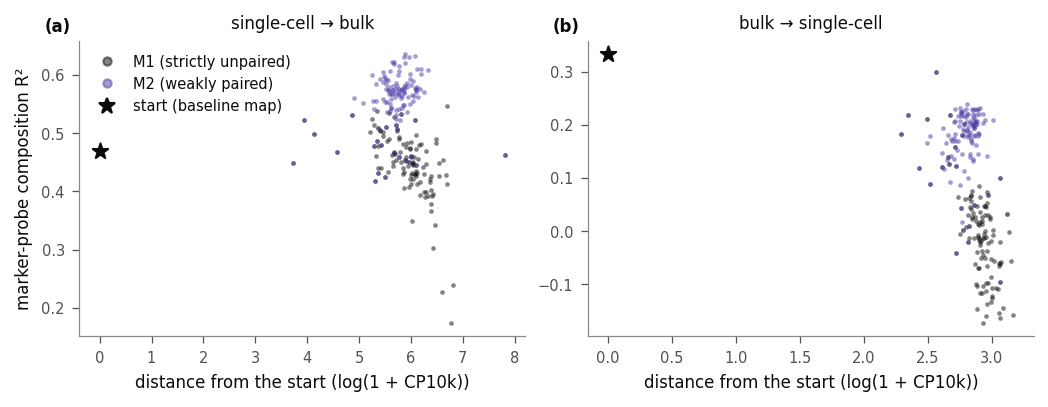

**At the same distance from its start, the weakly paired model carries more composition than the strictly unpaired one.** Composition R² under the marker probe (a ridge readout of the six cell-type fractions from 28 lineage marker genes; higher is better) against the distance from the start: the mean over validation sources of the Euclidean distance of the translation from the generator's starting map (mean shift in single-cell → bulk, ComBat in bulk → single-cell), in log(1 + CP10k) units over the 5,000-gene panel: (a) single-cell → bulk, (b) bulk → single-cell. Points are every evaluation after step 0 of the strictly unpaired model (M1, gray) and the weakly paired model (M2, purple), seeds 3–5, on the 135 validation pairs (14 donors); the star is the start. Both models move a similar distance from the start. M1 ends below the start's composition; M2 ends above it in single-cell → bulk and below it in bulk → single-cell. At the same distance M2 carries more composition, so its gain is not explained by moving less.

In [15]:
# Figure 4.2: composition (marker probe) against the distance from the start over training, M1 (full model) and M2 (B0), seeds 3-5.
fig, ax = figure("double", 2.6, 1, 2)
for a, d in zip(ax, tr.DIRECTIONS):
    for name, col in (("full model", INK), ("B0 M2", SERIES[6])):
        for i, r in enumerate(RUNS[name]):
            ev = pd.DataFrame([{k: v for k, v in e.items() if k != "ema"} for e in r["evals"]])
            ev = ev[ev.step > 0]                                    # the start (distance 0) is shown as a star
            a.scatter(ev[f"{d} drift"], ev[f"{d} marker comp_r2"], s=5, color=col, alpha=0.5, lw=0, label=("M1 (strictly unpaired)" if name == "full model" else "M2 (weakly paired)") if i == 0 else None)
    st = pd.DataFrame([{k: v for k, v in e.items() if k != "ema"} for e in RUNS["full model"][0]["evals"]]).iloc[0]
    a.scatter(0, st[f"{d} marker comp_r2"], s=60, marker="*", color=INK, label="start (baseline map)" if d == "S->B" else None)
    a.set(xlabel="distance from the start (log(1 + CP10k))", ylabel="marker-probe composition R²" if d == "S->B" else "", title=label(d))
ax[0].legend(handles=[Line2D([], [], ls="", marker="o", ms=4, color=INK, alpha=0.5, label="M1 (strictly unpaired)"),
                      Line2D([], [], ls="", marker="o", ms=4, color=SERIES[6], alpha=0.5, label="M2 (weakly paired)"),
                      Line2D([], [], ls="", marker="*", ms=8, color=INK, label="start (baseline map)")])
panel_labels(ax)
save_show(fig, FIG, "4.2_composition_vs_drift")
show_caption("4.2_composition_vs_drift")

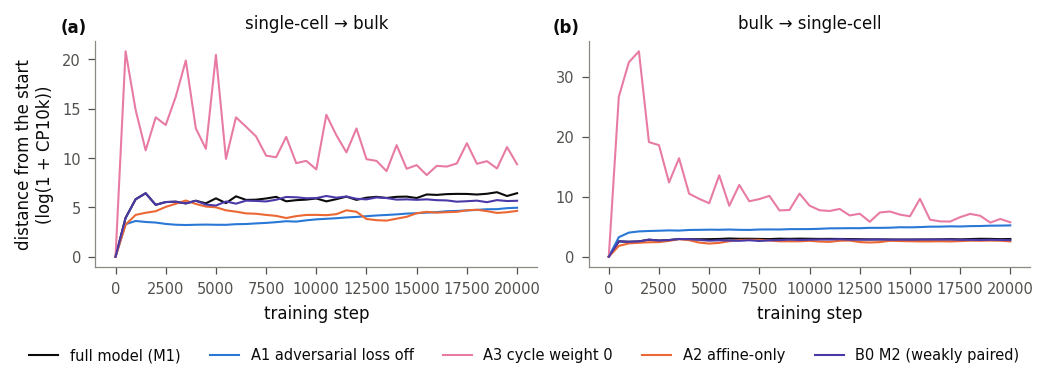

**Without the cycle loss the generators leave the data; without the adversarial loss they still drift from their starts.** Mean Euclidean distance of the translations of the 135 validation sources (14 donors) from the generator's starting map (mean shift in single-cell → bulk, ComBat in bulk → single-cell), in log(1 + CP10k) units, over training, mean over seeds 3–5: (a) single-cell → bulk, (b) bulk → single-cell. Lines: the locked strictly unpaired model (full model, M1), the model without the adversarial loss (A1), with cycle weight 0 (A3), with an affine-only generator (A2), and the weakly paired model (B0 M2). Without the adversarial loss, the cycle and identity losses alone still move the generators away from their starts (less far than the full model in single-cell → bulk, further in bulk → single-cell), with no gain in realism (Figure 4.1).

In [16]:
# Figure 4.3: mean distance of the translations from the start over training (mean over seeds 3-5).
fig, ax = figure("double", 2.4, 1, 2)
for a, d in zip(ax, tr.DIRECTIONS):
    for name in ("full model", "A1 adversarial loss off", "A3 cycle weight 0", "A2 affine-only", "B0 M2"):
        ev = pd.concat([pd.DataFrame([{k: v for k, v in e.items() if k != "ema"} for e in r["evals"]]) for r in RUNS[name]]).groupby("step").mean(numeric_only=True)
        a.plot(ev.index, ev[f"{d} drift"], color=MARK[name][0], lw=1.0, label=LEG.get(name, name) if d == "S->B" else None)
    a.set(xlabel="training step", ylabel="distance from the start\n(log(1 + CP10k))" if d == "S->B" else "", title=label(d))
fig.legend(loc="outside lower center", ncol=5)
panel_labels(ax)
save_show(fig, FIG, "4.3_drift")
show_caption("4.3_drift")

## 5. Conclusions

- **On fresh seeds the locked strictly unpaired model sits on the frontier** (last-quarter margin −0.001 ± 0.050 and −0.023 ± 0.039 over 3 seeds).
- **The discriminator buys realism; with it, the cycle loss keeps the generators near the data.** Without the adversarial loss, realism stays at the starts' level while the cycle and identity losses alone move the generators in a direction that costs accuracy (centered R² down 0.191, 95% CI 0.082–0.312, and 1.383, 95% CI 0.952–1.597, at the kept checkpoints). Removing the identity loss raises single-cell → bulk composition (+0.071, 95% CI 0.024–0.142) and lowers bulk → single-cell composition (−0.112, 95% CI −0.283 to 0.002).
- **Under these losses an affine-only generator does not become realistic, and M1's move is mostly orthogonal to the needed correction,** with a sample-specific component of 0.072 and 0.152 against 0.154 and 0.279 for paired ridge + spread.
- **Composition supervision helps on fresh seeds** (at the kept checkpoints, +0.160, 95% CI 0.118–0.260, and +0.196, 95% CI 0.074–0.397). With composition networks retrained on half A, the last-quarter gain survives in bulk → single-cell (+0.182 against +0.203), where the task targets become out-of-sample labels, and halves in single-cell → bulk (+0.075 against +0.167), where only the readout network changes; each task term alone gives most of it.
- **Halving the data costs realism whether donors or draws are removed** and, in bulk → single-cell, raises accuracy: a move along the trade-off. Donors may matter more in bulk → single-cell (margin −0.166 against −0.078), but seed SDs are large.
- **The realism measure:** of the 50-PC alternatives, only the gradient-boosted classifier in bulk → single-cell passes calibration, and it puts M1 inside the frontier there (−0.167).

**Implications.**
- Weight averaging improves margin and accuracy in every seed and both directions (+0.031 and +0.018 in mean margin) at no cost in realism (composition was not measured for the averaged weights): the safest Phase 5 lever.
- Moving less is not by itself the lever. The full model moves further than the model without the discriminator but loses less accuracy, and less data trades realism for accuracy along the frontier, so a plain penalty on the distance from the start would most likely trade along the frontier too. A loss that changes the direction of the move, such as an identity loss anchored to the start (the output compared with the start's output rather than with the input), is a hypothesis worth testing.
- These results concern deterministic moves; they do not rule out a noise input or diffusion, which would need to add sample-specific signal, not only spread.
- At equal distance from the start, M2 carries more composition than M1, so its gain is not explained by moving less (Figure 4.2). In bulk → single-cell the start itself still carries more composition than M2 (0.333, Phase 3 Table 3.6, against 0.216, Table 4.3), so anchoring is not ruled out there. M2's gain in bulk → single-cell holds with out-of-sample labels.
- The H1 measure remains the realism reference for Phase 5; in bulk → single-cell the gradient-boosted measure is a usable second reading.
- The Phase 3 hypotheses on test still apply only to the locked M1 and M2. Any Phase 5 model sent to test is exploratory, and is reported with the total number of configurations compared on validation.


## 6. Limitations

- **Validation only, on the donors that chose the locked models.** The donor-bootstrap CIs cover donor sampling but not training noise, and are optimistic.
- **Three seeds per condition.** Several differences in margin (seed SDs up to 0.19) are within noise, and no claims are attached to them.
- **B3 changes label quality and network training size together** (288 rather than 582 pairs); a cross-fitted network would separate the two.
- **The data-size ablation keeps 20,000 steps,** so the reduced sets are seen about twice as often, and each condition uses one subset per seed.
- **No alternative realism measure is usable in single-cell → bulk** (the 50-PC classifiers fail calibration and MMD has none), so whether "on the frontier" depends on the realism measure is answered only in bulk → single-cell, where the H1 measure's own calibration is close to its limit (0.611 against 0.633).
- **Not explored:** the other training halving, the discriminator, the generator's width, and the training length.


## 7. Reproducibility

Each run took 32–99 minutes on CPU; the 42 runs (3 equivalence runs, 27 for M1's conditions, 6 for M2 and B3, and 6 for B1 and B2) took about 9 hours with 6 workers of 4 threads each on a 24-thread Intel Core Ultra 9 275HX. Runs are deterministic and cached in `data/processed/phase4/` under a key covering the code (`dgm/translation.py`, `dgm/ablation.py` and the modules they use), the Phase 1 frontier, the Phase 2 and Phase 4 model registries, the pairs file and the library versions; delete the cache to recompute. With a full cache the notebook runs in about 30 minutes, mostly the analyses of §4.5–4.6. The half-A composition networks are in `data/models/phase4/`, with their hashes in `results/phase4/models.json`. Known-answer tests: `python -m tests.test_ablation` (set `PHASE4_SLOW=1` to also check the frontier refit against Phase 1).

Outputs in `results/phase4/`:
- `half_nets_val.csv` (Table 4.1); `ablation_runs_val.csv` (every readout per run), `ablation_means_val.csv`, `ablation_sd_val.csv`, `ablation_diff_val.csv` (means, SDs and differences per condition), `ablation_ci_val.csv` (Table 4.4), `ablation_terms_runs_val.csv` (B1 and B2), `grid_slices_val.csv` (Table 4.6).
- `a4_subsets.csv` and `a4_subset_rows.json` (the reduced training sets, by sample).
- `p0_move_decomposition_val.csv` (Table 4.9); `p1_calibration_val.csv`, `p1_margins_val.csv`, `p1_frontiers_val.csv` (Tables 4.10–4.11 and the frontiers under each measure); `ema_last_quarter_val.csv` (Table 4.12).
- `figures/`: Figures 4.1–4.3 as PNG and PDF, with their captions in `captions.md`.

## References

- Gretton, A., Borgwardt, K. M., Rasch, M. J., Schölkopf, B. & Smola, A. A kernel two-sample test. *Journal of Machine Learning Research* 13, 723–773 (2012).
- Hoffman, J., Tzeng, E., Park, T., Zhu, J.-Y., Isola, P., Saenko, K., Efros, A. A. & Darrell, T. CyCADA: cycle-consistent adversarial domain adaptation. *ICML* (2018).
- Johnson, W. E., Li, C. & Rabinovic, A. Adjusting batch effects in microarray expression data using empirical Bayes methods. *Biostatistics* 8, 118–127 (2007).
- Lopez-Paz, D. & Oquab, M. Revisiting classifier two-sample tests. *ICLR* (2017).
- Mao, X., Li, Q., Xie, H., Lau, R. Y. K., Wang, Z. & Smolley, S. P. Least squares generative adversarial networks. *ICCV*, 2813–2821 (2017).
- Sun, B., Feng, J. & Saenko, K. Return of frustratingly easy domain adaptation. *AAAI* (2016).
- Zhu, J.-Y., Park, T., Isola, P. & Efros, A. A. Unpaired image-to-image translation using cycle-consistent adversarial networks. *ICCV* (2017).